In [26]:
# Imports and project configuration
import os
import math
import random
import time
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.utils import make_grid

warnings.filterwarnings("once")
plt.style.use("dark_background")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = Path("./data")
CHECKPOINT_DIR = Path("./checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 64
LOW_RES_SIZE = 16
BATCH_SIZE = 64 if device.type == "cuda" else 32
NUM_WORKERS = 0
PIN_MEMORY = device.type == "cuda"

TIMESTEPS = 1000
MODEL_CHANNELS = 64
CHANNEL_MULT = (1, 2, 4, 4)
ATTENTION_RESOLUTIONS = (16, 8)
USE_IMAGENET_PRETRAINED = True
USE_AMP = True

TRAIN_SUPERRES = True
TRAIN_COLORIZATION = True
SUPERRES_EPOCHS = 40
COLORIZATION_EPOCHS = 40

print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"Image size: {IMAGE_SIZE}x{IMAGE_SIZE} | LR size: {LOW_RES_SIZE}x{LOW_RES_SIZE}")
print(f"Batch size: {BATCH_SIZE} | AMP enabled: {USE_AMP and device.type == 'cuda'}")

Device: cuda
PyTorch: 2.11.0+cu130
Image size: 64x64 | LR size: 16x16
Batch size: 64 | AMP enabled: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
# CIFAR-10
print("Loading CIFAR-10...")
cifar_train_base = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=True)
cifar_test_base = datasets.CIFAR10(root=str(DATA_ROOT), train=False, download=True)

class QuickDataset(Dataset):
    """Create paired (bicubic-upsampled LR, HR) images from CIFAR-10.

    Important limitation: CIFAR-10 images are natively 32x32. Resizing them to
    64x64 creates a controlled synthetic benchmark, not genuine 64x64 detail.
    The LR input is produced by downsampling to LOW_RES_SIZE and upsampling back.
    """
    def __init__(self, base_dataset, image_size=IMAGE_SIZE, low_res_size=LOW_RES_SIZE):
        self.data = base_dataset
        self.image_size = image_size
        self.low_res_size = low_res_size
        self.normalize = transforms.Normalize([0.5] * 3, [0.5] * 3)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, _ = self.data[idx]
        image = TF.resize(
            image,
            [self.image_size, self.image_size],
            interpolation=TF.InterpolationMode.BICUBIC,
            antialias=True,
        )
        hr = TF.to_tensor(image)
        lr_small = F.interpolate(
            hr.unsqueeze(0),
            size=(self.low_res_size, self.low_res_size),
            mode="bicubic",
            align_corners=False,
            antialias=True,
        )
        lr = F.interpolate(
            lr_small,
            size=(self.image_size, self.image_size),
            mode="bicubic",
            align_corners=False,
        ).squeeze(0)
        return self.normalize(lr), self.normalize(hr)

sr_full_train_dataset = QuickDataset(cifar_train_base)
sr_test_dataset = QuickDataset(cifar_test_base)

train_size = int(0.9 * len(sr_full_train_dataset))
val_size = len(sr_full_train_dataset) - train_size
sr_train_dataset, sr_val_dataset = random_split(
    sr_full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED),
)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
}
sr_train_loader = DataLoader(sr_train_dataset, shuffle=True, **loader_kwargs)
sr_val_loader = DataLoader(sr_val_dataset, shuffle=False, **loader_kwargs)
sr_test_loader = DataLoader(sr_test_dataset, shuffle=False, **loader_kwargs)

print("=" * 68)
print(f"Training pairs:   {len(sr_train_dataset):,}")
print(f"Validation pairs: {len(sr_val_dataset):,}")
print(f"Test pairs:       {len(sr_test_dataset):,}")
print(f"Train batches:    {len(sr_train_loader):,}")
print("=" * 68)

lr_sample, hr_sample = sr_train_dataset[0]
print(f"Sample shapes: LR={tuple(lr_sample.shape)}, HR={tuple(hr_sample.shape)}")

Loading CIFAR-10...


100%|██████████| 170M/170M [35:21<00:00, 80.4kB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/datasets/utils.py:213: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(to_path)


Training pairs:   45,000
Validation pairs: 5,000
Test pairs:       10,000
Train batches:    704
Sample shapes: LR=(3, 64, 64), HR=(3, 64, 64)


##dataset Loaded and Ready


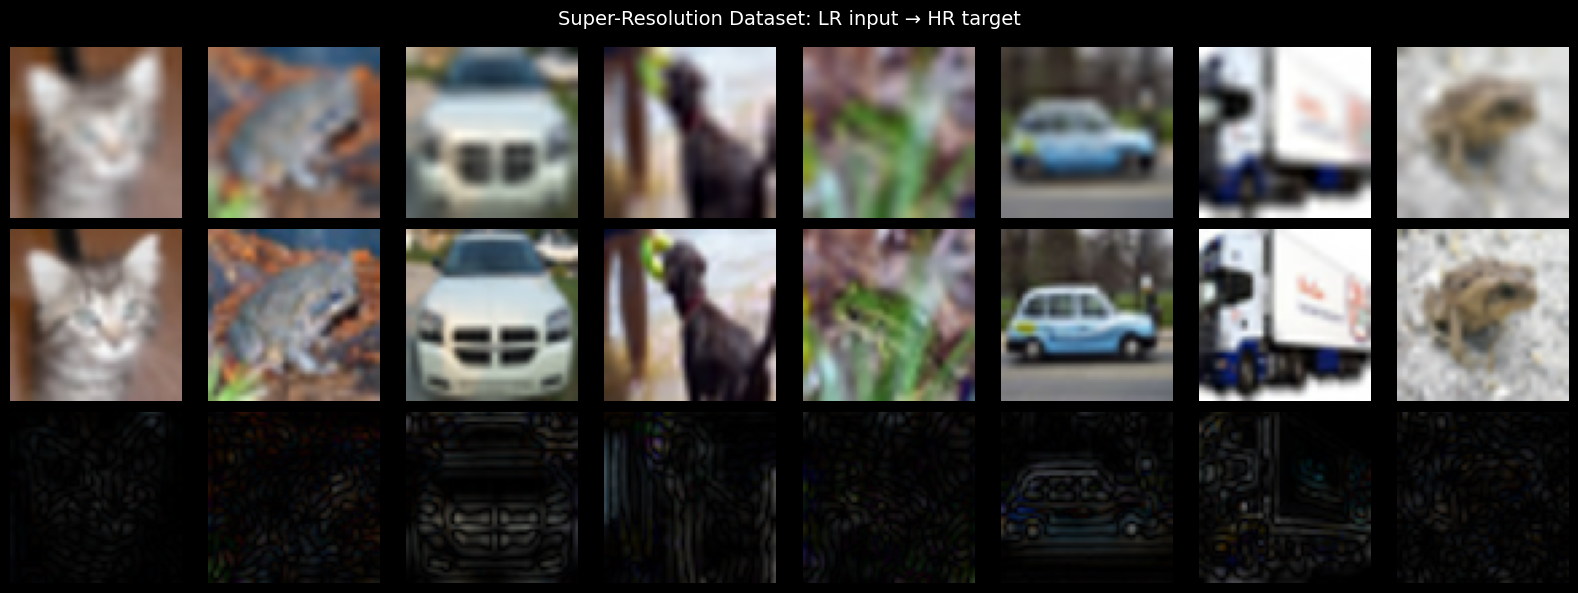

In [27]:
# Visual inspection of paired samples
low_res_batch, high_res_batch = next(iter(sr_train_loader))
num_show = min(8, len(low_res_batch))
fig, axes = plt.subplots(3, num_show, figsize=(2 * num_show, 6))
fig.suptitle("Super-Resolution Dataset: LR input → HR target", fontsize=14)

for i in range(num_show):
    low_img = ((low_res_batch[i].cpu() + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()
    high_img = ((high_res_batch[i].cpu() + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy()
    diff = np.abs(high_img - low_img)
    axes[0, i].imshow(low_img)
    axes[1, i].imshow(high_img)
    axes[2, i].imshow(diff)
    for row in range(3):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("Low-Res", rotation=0, ha="right", va="center")
axes[1, 0].set_ylabel("High-Res", rotation=0, ha="right", va="center")
axes[2, 0].set_ylabel("Absolute difference", rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()

##Diffusion Schedule



Diffusion schedule initialized with 1000 timesteps
Beta range: [0.000100, 0.020000]


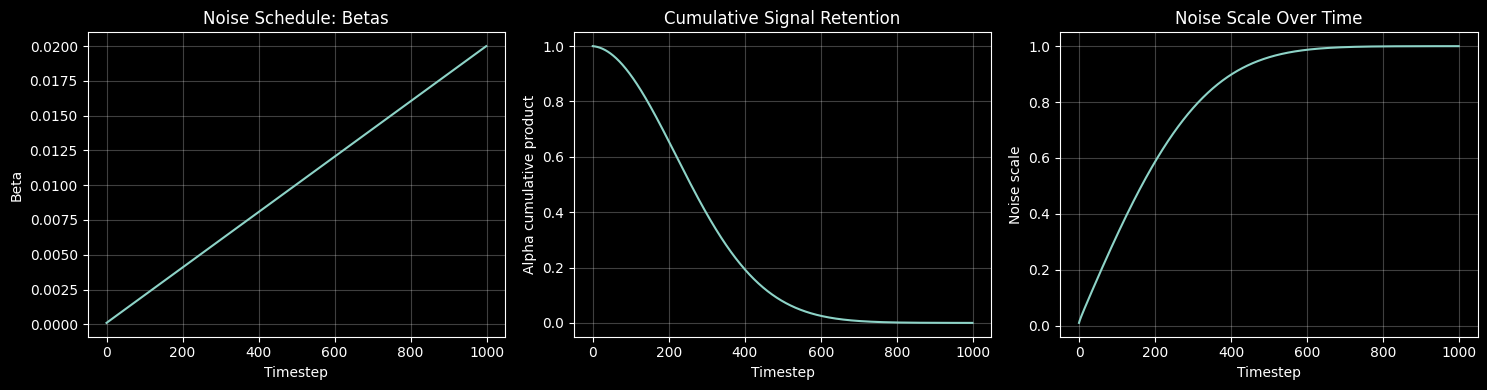

In [28]:
class DiffusionSchedule:
    """DDPM forward process and DDPM/DDIM reverse-process coefficients."""
    def __init__(self, timesteps=TIMESTEPS, beta_start=1e-4, beta_end=0.02, device=device):
        self.timesteps = int(timesteps)
        self.device = torch.device(device)
        self.betas = torch.linspace(beta_start, beta_end, self.timesteps, device=self.device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0), value=1.0)
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)
        self.sqrt_recip_alphas = torch.rsqrt(self.alphas)
        self.posterior_variance = (
            self.betas * (1.0 - self.alphas_cumprod_prev)
            / (1.0 - self.alphas_cumprod).clamp_min(1e-12)
        ).clamp_min(1e-20)

    def add_noise(self, x_0, t, noise):
        sqrt_alpha = self.sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
        sqrt_one_minus = self.sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)
        return sqrt_alpha * x_0 + sqrt_one_minus * noise

    def sample_prev_step(self, x_t, t, predicted_noise):
        """One full DDPM reverse step. Intended for the complete schedule."""
        beta_t = self.betas[t].view(-1, 1, 1, 1)
        sqrt_recip_alpha = self.sqrt_recip_alphas[t].view(-1, 1, 1, 1)
        sqrt_one_minus = self.sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)
        model_mean = sqrt_recip_alpha * (
            x_t - beta_t * predicted_noise / sqrt_one_minus.clamp_min(1e-12)
        )
        variance = self.posterior_variance[t].view(-1, 1, 1, 1)
        noise = torch.randn_like(x_t)
        nonzero_mask = (t > 0).float().view(-1, 1, 1, 1)
        return model_mean + nonzero_mask * torch.sqrt(variance) * noise

    def ddim_step(self, x_t, timestep, previous_timestep, predicted_noise, eta=0.0):
        """DDIM update for arbitrary selected timestep pairs."""
        alpha_t = self.alphas_cumprod[timestep]
        alpha_prev = (
            self.alphas_cumprod[previous_timestep]
            if previous_timestep >= 0
            else torch.tensor(1.0, device=x_t.device)
        )
        pred_x0 = (x_t - torch.sqrt(1.0 - alpha_t) * predicted_noise) / torch.sqrt(alpha_t)
        pred_x0 = pred_x0.clamp(-1.0, 1.0)
        sigma = eta * torch.sqrt(
            ((1.0 - alpha_prev) / (1.0 - alpha_t).clamp_min(1e-12))
            * (1.0 - alpha_t / alpha_prev)
        ).clamp_min(0.0)
        direction = torch.sqrt((1.0 - alpha_prev - sigma.square()).clamp_min(0.0)) * predicted_noise
        noise = torch.randn_like(x_t) if eta > 0 else torch.zeros_like(x_t)
        return torch.sqrt(alpha_prev) * pred_x0 + direction + sigma * noise

schedule = DiffusionSchedule(timesteps=TIMESTEPS, device=device)
print(f"Diffusion schedule initialized with {schedule.timesteps} timesteps")
print(f"Beta range: [{schedule.betas[0].item():.6f}, {schedule.betas[-1].item():.6f}]")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
t_values = torch.arange(schedule.timesteps).cpu()
axes[0].plot(t_values, schedule.betas.cpu())
axes[0].set(title="Noise Schedule: Betas", xlabel="Timestep", ylabel="Beta")
axes[1].plot(t_values, schedule.alphas_cumprod.cpu())
axes[1].set(title="Cumulative Signal Retention", xlabel="Timestep", ylabel="Alpha cumulative product")
axes[2].plot(t_values, schedule.sqrt_one_minus_alphas_cumprod.cpu())
axes[2].set(title="Noise Scale Over Time", xlabel="Timestep", ylabel="Noise scale")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

##pre-trained Feature Extractor



In [29]:
class FeatureExtractor(nn.Module):
    """Frozen ResNet-50 feature pyramid for RGB or grayscale conditions."""
    feature_channels = {"layer1": 256, "layer2": 512, "layer3": 1024, "layer4": 2048}

    def __init__(self, use_pretrained=USE_IMAGENET_PRETRAINED):
        super().__init__()
        weights = ResNet50_Weights.DEFAULT if use_pretrained else None
        try:
            backbone = resnet50(weights=weights)
        except Exception as exc:
            warnings.warn(
                f"Could not load pretrained ResNet-50 weights ({exc}). "
                "Falling back to randomly initialized frozen weights. "
                "For portfolio experiments, rerun where ImageNet weights are available."
            )
            backbone = resnet50(weights=None)

        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        for parameter in self.parameters():
            parameter.requires_grad = False
        self.eval()

    def forward(self, x):
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)
        elif x.shape[1] != 3:
            raise ValueError(f"Expected 1 or 3 condition channels, got {x.shape[1]}")

        x = ((x + 1.0) / 2.0).clamp(0, 1)
        x = (x - self.mean) / self.std
        with torch.no_grad():
            x = self.stem(x)
            f1 = self.layer1(x)
            f2 = self.layer2(f1)
            f3 = self.layer3(f2)
            f4 = self.layer4(f3)
        return {"layer1": f1, "layer2": f2, "layer3": f3, "layer4": f4}

feature_extractor = FeatureExtractor().to(device).eval()
test_img = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
test_features = feature_extractor(test_img)
print("Multi-scale feature extraction test:")
for name, feature in test_features.items():
    print(f"  {name}: {tuple(feature.shape)}")

Multi-scale feature extraction test:
  layer1: (2, 256, 16, 16)
  layer2: (2, 512, 8, 8)
  layer3: (2, 1024, 4, 4)
  layer4: (2, 2048, 2, 2)


##U-Net for Diffusion



In [30]:
def groups_for(channels, maximum=8):
    """Choose a valid GroupNorm group count that divides channels."""
    for groups in range(min(maximum, channels), 0, -1):
        if channels % groups == 0:
            return groups
    return 1

class TimestepEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = max(self.dim // 2, 1)
        exponent = -math.log(10000) / max(half_dim - 1, 1)
        frequencies = torch.exp(torch.arange(half_dim, device=t.device, dtype=torch.float32) * exponent)
        embeddings = t.float()[:, None] * frequencies[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        if embeddings.shape[-1] < self.dim:
            embeddings = F.pad(embeddings, (0, self.dim - embeddings.shape[-1]))
        return embeddings

class ResNetBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups_for(in_channels), in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_channels))
        self.norm2 = nn.GroupNorm(groups_for(out_channels), out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.residual = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_mlp(time_embedding)[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.residual(x)

class SelfAttention(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        if channels % num_heads != 0:
            num_heads = 1
        self.num_heads = num_heads
        self.norm = nn.GroupNorm(groups_for(channels), channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        batch, channels, height, width = x.shape
        head_dim = channels // self.num_heads
        qkv = self.qkv(self.norm(x)).reshape(
            batch, 3, self.num_heads, head_dim, height * width
        ).permute(1, 0, 2, 4, 3)
        q, k, v = qkv.unbind(0)
        if hasattr(F, "scaled_dot_product_attention"):
            attended = F.scaled_dot_product_attention(q, k, v)
        else:
            scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(head_dim)
            attended = torch.matmul(torch.softmax(scores, dim=-1), v)
        attended = attended.permute(0, 1, 3, 2).reshape(batch, channels, height, width)
        return x + self.proj(attended)

class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)
    def forward(self, x, size=None):
        if size is None:
            size = (x.shape[-2] * 2, x.shape[-1] * 2)
        return self.conv(F.interpolate(x, size=size, mode="nearest"))

class ConditionalUNet(nn.Module):
    """Conditional U-Net with multi-scale frozen ResNet feature fusion."""
    def __init__(
        self,
        in_channels=3,
        condition_channels=3,
        model_channels=MODEL_CHANNELS,
        out_channels=3,
        channel_mult=CHANNEL_MULT,
        num_res_blocks=2,
        attention_resolutions=ATTENTION_RESOLUTIONS,
        dropout=0.1,
        use_multiscale_features=True,
    ):
        super().__init__()
        self.condition_channels = condition_channels
        self.use_multiscale_features = use_multiscale_features
        time_dim = model_channels * 4
        self.time_embedding = nn.Sequential(
            TimestepEmbedding(model_channels),
            nn.Linear(model_channels, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input_proj = nn.Conv2d(in_channels + condition_channels, model_channels, 3, padding=1)

        stage_channels = [model_channels * multiplier for multiplier in channel_mult]
        self.down_blocks = nn.ModuleList()
        self.down_attentions = nn.ModuleList()
        self.downsamples = nn.ModuleList()
        current_channels = model_channels

        for level, out_ch in enumerate(stage_channels):
            blocks = nn.ModuleList()
            for _ in range(num_res_blocks):
                blocks.append(ResNetBlock(current_channels, out_ch, time_dim, dropout))
                current_channels = out_ch
            self.down_blocks.append(blocks)
            resolution = IMAGE_SIZE // (2 ** level)
            self.down_attentions.append(
                SelfAttention(out_ch) if resolution in attention_resolutions else nn.Identity()
            )
            if level < len(stage_channels) - 1:
                self.downsamples.append(Downsample(out_ch))

        resnet_channels = [256, 512, 1024, 2048]
        self.feature_projections = nn.ModuleList()
        if use_multiscale_features:
            for source_ch, target_ch in zip(resnet_channels, stage_channels):
                projection = nn.Conv2d(source_ch, target_ch, 1)
                nn.init.zeros_(projection.weight)
                nn.init.zeros_(projection.bias)
                self.feature_projections.append(projection)

        self.middle_block1 = ResNetBlock(current_channels, current_channels, time_dim, dropout)
        self.middle_attention = SelfAttention(current_channels)
        self.middle_block2 = ResNetBlock(current_channels, current_channels, time_dim, dropout)

        self.up_blocks = nn.ModuleList()
        self.up_attentions = nn.ModuleList()
        self.upsamples = nn.ModuleList()
        for level in reversed(range(len(stage_channels))):
            out_ch = stage_channels[level]
            self.up_blocks.append(nn.ModuleList([
                ResNetBlock(current_channels + out_ch, out_ch, time_dim, dropout),
                ResNetBlock(out_ch, out_ch, time_dim, dropout),
            ]))
            current_channels = out_ch
            resolution = IMAGE_SIZE // (2 ** level)
            self.up_attentions.append(
                SelfAttention(out_ch) if resolution in attention_resolutions else nn.Identity()
            )
            if level > 0:
                self.upsamples.append(Upsample(out_ch))

        self.output = nn.Sequential(
            nn.GroupNorm(groups_for(current_channels), current_channels),
            nn.SiLU(),
            nn.Conv2d(current_channels, out_channels, 3, padding=1),
        )

    def forward(self, x_noisy, t, condition, resnet_features=None):
        if condition.shape[1] != self.condition_channels:
            raise ValueError(
                f"Expected {self.condition_channels} condition channels, got {condition.shape[1]}"
            )
        h = self.input_proj(torch.cat([x_noisy, condition], dim=1))
        skips = []

        for level, blocks in enumerate(self.down_blocks):
            for block in blocks:
                h = block(h, self.time_embedding(t))
            if self.use_multiscale_features and resnet_features is not None:
                feature_name = f"layer{level + 1}"
                feature = self.feature_projections[level](resnet_features[feature_name])
                feature = F.interpolate(feature, size=h.shape[-2:], mode="bilinear", align_corners=False)
                h = h + feature
            h = self.down_attentions[level](h)
            skips.append(h)
            if level < len(self.downsamples):
                h = self.downsamples[level](h)

        h = self.middle_block1(h, self.time_embedding(t))
        h = self.middle_attention(h)
        h = self.middle_block2(h, self.time_embedding(t))

        upsample_index = 0
        for block_index, level in enumerate(reversed(range(len(self.up_blocks)))):
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                h = F.interpolate(h, size=skip.shape[-2:], mode="nearest")
            h = torch.cat([h, skip], dim=1)
            for block in self.up_blocks[block_index]:
                h = block(h, self.time_embedding(t))
            h = self.up_attentions[block_index](h)
            if level > 0:
                next_size = (IMAGE_SIZE // (2 ** (level - 1)), IMAGE_SIZE // (2 ** (level - 1)))
                h = self.upsamples[upsample_index](h, size=next_size)
                upsample_index += 1

        return self.output(h)

unet = ConditionalUNet(condition_channels=3).to(device)
parameter_count = sum(parameter.numel() for parameter in unet.parameters())
trainable_count = sum(parameter.numel() for parameter in unet.parameters() if parameter.requires_grad)
print(f"Conditional U-Net created: {parameter_count / 1e6:.2f}M total parameters")
print(f"Trainable parameters: {trainable_count / 1e6:.2f}M")

test_noisy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
test_condition = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
test_t = torch.randint(0, TIMESTEPS, (2,), device=device)
with torch.no_grad():
    test_features = feature_extractor(test_condition)
    test_output = unet(test_noisy, test_t, test_condition, test_features)
print(f"Forward pass output shape: {tuple(test_output.shape)}")
assert test_output.shape == test_noisy.shape

Conditional U-Net created: 20.07M total parameters
Trainable parameters: 20.07M
Forward pass output shape: (2, 3, 64, 64)


##Super-Resolution Model


Training: superres
Epochs: 40 | AMP: True | Checkpoints: checkpoints


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 001/40 | train=0.075126 | val=0.016604 | lr=9.98e-05
  Saved best checkpoint: checkpoints/superres_best.pt


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

... (111 outputs left out)

Epoch 039/40 | train=0.005126 | val=0.004641 | lr=1.54e-07


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 040/40 | train=0.004958 | val=0.004846 | lr=0.00e+00
Best validation loss: 0.004352


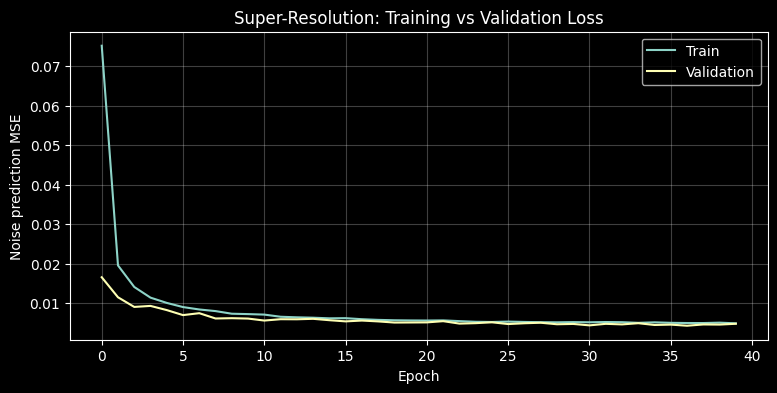

In [31]:
def _run_diffusion_epoch(unet, feature_extractor, dataloader, schedule, optimizer=None,
                         scaler=None, use_amp=False, seed=None):
    training = optimizer is not None
    unet.train(training)
    feature_extractor.eval()
    total_loss = 0.0
    total_items = 0
    generator = None
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)

    context = torch.enable_grad if training else torch.no_grad
    with context():
        for condition, target in tqdm(dataloader, leave=False):
            condition = condition.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            batch_size = target.shape[0]
            if generator is None:
                timesteps = torch.randint(0, schedule.timesteps, (batch_size,), device=device)
                noise = torch.randn_like(target)
            else:
                timesteps = torch.randint(0, schedule.timesteps, (batch_size,), device=device, generator=generator)
                noise = torch.randn(target.shape, device=device, dtype=target.dtype, generator=generator)
            noisy_target = schedule.add_noise(target, timesteps, noise)

            with torch.no_grad():
                features = feature_extractor(condition)

            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16 if device.type == "cuda" else torch.bfloat16,
                enabled=bool(use_amp and device.type == "cuda"),
            ):
                predicted_noise = unet(noisy_target, timesteps, condition, features)
                loss = F.mse_loss(predicted_noise.float(), noise.float())

            if training:
                if scaler is not None and scaler.is_enabled():
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
                    optimizer.step()

            total_loss += loss.detach().item() * batch_size
            total_items += batch_size

    if total_items == 0:
        raise RuntimeError("The provided DataLoader is empty.")
    return total_loss / total_items


def train_conditional_diffusion(unet, feature_extractor, train_loader, val_loader, schedule,
                                task_name, epochs=40, lr=1e-4, weight_decay=1e-4,
                                checkpoint_dir=CHECKPOINT_DIR, use_amp=USE_AMP):
    """Reusable, validation-aware trainer for both restoration tasks."""
    if val_loader is None:
        raise ValueError("A validation DataLoader is required for model selection.")
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    optimizer = optim.AdamW(unet.parameters(), lr=lr, weight_decay=weight_decay)
    lr_scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    amp_enabled = bool(use_amp and device.type == "cuda")
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    except (AttributeError, TypeError):  # Compatibility with older PyTorch 2.x releases
        scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    history = {"train_loss": [], "val_loss": [], "learning_rate": []}
    best_val_loss = float("inf")
    best_path = checkpoint_dir / f"{task_name}_best.pt"
    last_path = checkpoint_dir / f"{task_name}_last.pt"

    print("=" * 72)
    print(f"Training: {task_name}")
    print(f"Epochs: {epochs} | AMP: {amp_enabled} | Checkpoints: {checkpoint_dir}")
    print("=" * 72)

    for epoch in range(1, epochs + 1):
        train_loss = _run_diffusion_epoch(
            unet, feature_extractor, train_loader, schedule,
            optimizer=optimizer, scaler=scaler, use_amp=amp_enabled,
        )
        val_loss = _run_diffusion_epoch(
            unet, feature_extractor, val_loader, schedule,
            optimizer=None, use_amp=False, seed=SEED + epoch,
        )
        lr_scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["learning_rate"].append(current_lr)

        print(
            f"Epoch {epoch:03d}/{epochs} | train={train_loss:.6f} "
            f"| val={val_loss:.6f} | lr={current_lr:.2e}"
        )

        checkpoint = {
            "epoch": epoch,
            "task_name": task_name,
            "model_state_dict": unet.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "history": history,
            "image_size": IMAGE_SIZE,
            "timesteps": schedule.timesteps,
        }
        torch.save(checkpoint, last_path)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(checkpoint, best_path)
            print(f"  Saved best checkpoint: {best_path}")

    print(f"Best validation loss: {best_val_loss:.6f}")
    return history


def train_superres_diffusion(unet, feature_extractor, dataloader, val_dataloader, schedule,
                             epochs=40, lr=1e-4, use_amp=USE_AMP):
    return train_conditional_diffusion(
        unet, feature_extractor, dataloader, val_dataloader, schedule,
        task_name="superres", epochs=epochs, lr=lr, use_amp=use_amp,
    )

superres_history = None
if TRAIN_SUPERRES:
    superres_history = train_superres_diffusion(
        unet=unet,
        feature_extractor=feature_extractor,
        dataloader=sr_train_loader,
        val_dataloader=sr_val_loader,
        schedule=schedule,
        epochs=SUPERRES_EPOCHS,
        lr=1e-4,
    )
    plt.figure(figsize=(9, 4))
    plt.plot(superres_history["train_loss"], label="Train")
    plt.plot(superres_history["val_loss"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Noise prediction MSE")
    plt.title("Super-Resolution: Training vs Validation Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("Super-resolution training skipped. Set TRAIN_SUPERRES = True to start.")

##Reverse Diffusion Sampling



/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:684: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)


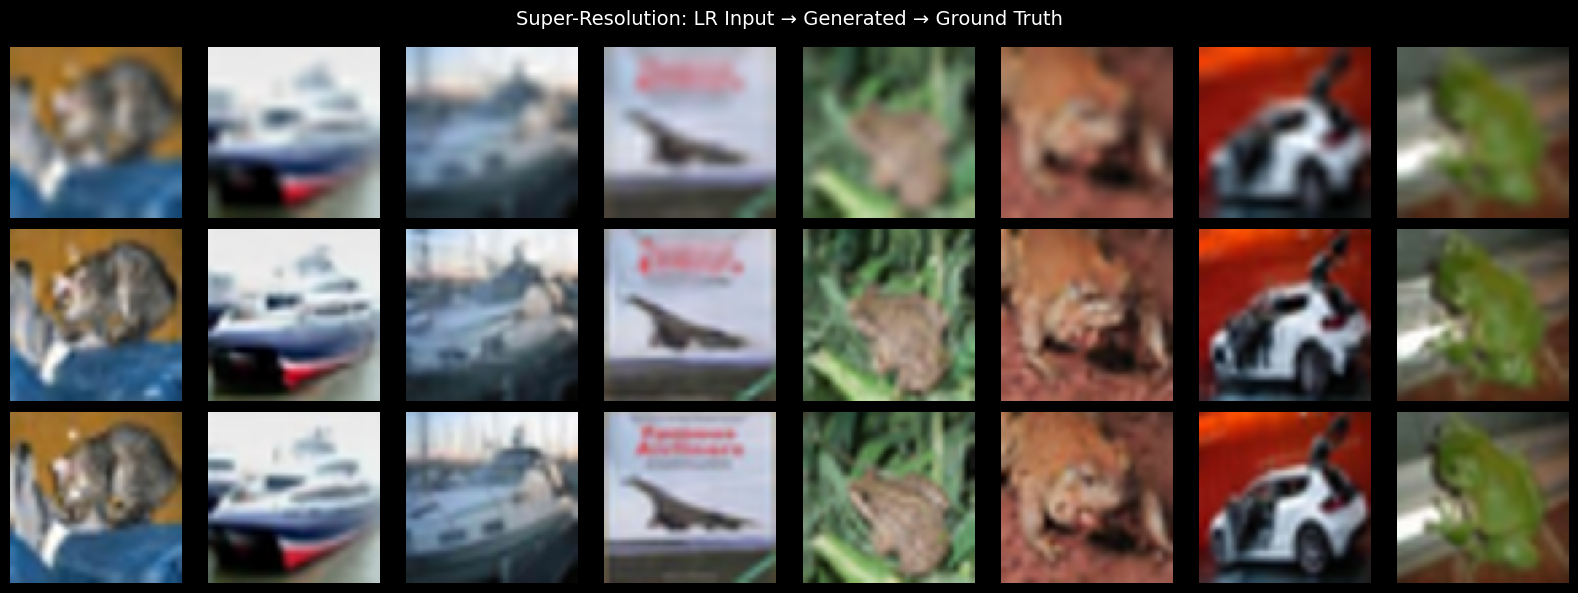

Held-out test metrics (mean over evaluated images):
  model_psnr: 27.5720
  model_ssim: 0.8513
  baseline_psnr: 27.2039
  baseline_ssim: 0.8402


In [37]:
@torch.no_grad()
def sample_conditional(unet, feature_extractor, schedule, condition, num_steps=50,
                       sampler="ddim", eta=0.0):
    unet.eval()
    feature_extractor.eval()
    batch_size = condition.shape[0]
    features = feature_extractor(condition)
    target_channels = unet.output[-1].out_channels
    x_t = torch.randn(batch_size, target_channels, IMAGE_SIZE, IMAGE_SIZE, device=condition.device)

    if sampler.lower() == "ddpm":
        if num_steps != schedule.timesteps:
            raise ValueError("DDPM reference sampling requires num_steps == schedule.timesteps.")
        selected_timesteps = list(range(schedule.timesteps - 1, -1, -1))
        for timestep in selected_timesteps:
            t = torch.full((batch_size,), timestep, device=condition.device, dtype=torch.long)
            predicted_noise = unet(x_t, t, condition, features)
            x_t = schedule.sample_prev_step(x_t, t, predicted_noise)
    elif sampler.lower() == "ddim":
        if not 1 <= num_steps <= schedule.timesteps:
            raise ValueError(f"num_steps must be between 1 and {schedule.timesteps}.")
        selected = torch.linspace(0, schedule.timesteps - 1, num_steps, device="cpu").long().unique().tolist()
        for index in reversed(range(len(selected))):
            timestep = selected[index]
            previous_timestep = selected[index - 1] if index > 0 else -1
            t = torch.full((batch_size,), timestep, device=condition.device, dtype=torch.long)
            predicted_noise = unet(x_t, t, condition, features)
            x_t = schedule.ddim_step(x_t, timestep, previous_timestep, predicted_noise, eta=eta)
    else:
        raise ValueError("sampler must be either 'ddpm' or 'ddim'.")
    return x_t.clamp(-1, 1)


def sample_superres(unet, feature_extractor, schedule, low_res_images,
                    num_steps=50, sampler="ddim", eta=0.0):
    return sample_conditional(
        unet, feature_extractor, schedule, low_res_images,
        num_steps=num_steps, sampler=sampler, eta=eta,
    )


def psnr_metric(prediction, target, data_range=1.0):
    prediction = prediction.clamp(0, data_range)
    target = target.clamp(0, data_range)
    mse = F.mse_loss(prediction, target, reduction="none").flatten(1).mean(dim=1)
    return 10.0 * torch.log10((data_range ** 2) / mse.clamp_min(1e-10))


def ssim_metric(prediction, target, data_range=1.0, window_size=11, sigma=1.5):
    """SSIM with a Gaussian local window, returned as one score per image."""
    x = prediction.clamp(0, data_range)
    y = target.clamp(0, data_range)
    channels = x.shape[1]
    coords = torch.arange(window_size, device=x.device, dtype=x.dtype) - (window_size - 1) / 2
    gaussian = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    gaussian = gaussian / gaussian.sum()
    window_2d = torch.outer(gaussian, gaussian)
    window = window_2d.view(1, 1, window_size, window_size).repeat(channels, 1, 1, 1)
    padding = window_size // 2
    mu_x = F.conv2d(x, window, padding=padding, groups=channels)
    mu_y = F.conv2d(y, window, padding=padding, groups=channels)
    mu_x2, mu_y2, mu_xy = mu_x.square(), mu_y.square(), mu_x * mu_y
    sigma_x2 = F.conv2d(x * x, window, padding=padding, groups=channels) - mu_x2
    sigma_y2 = F.conv2d(y * y, window, padding=padding, groups=channels) - mu_y2
    sigma_xy = F.conv2d(x * y, window, padding=padding, groups=channels) - mu_xy
    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2
    score = ((2 * mu_xy + c1) * (2 * sigma_xy + c2)) / (
        (mu_x2 + mu_y2 + c1) * (sigma_x2 + sigma_y2 + c2) + 1e-8
    )
    return score.flatten(1).mean(dim=1)


_LPIPS_MODELS = {}
def lpips_metric(prediction, target, network="alex"):
    """Optional perceptual metric. Install with `pip install lpips` before calling."""
    try:
        import lpips
    except ImportError as exc:
        raise ImportError("LPIPS is optional. Install it with `pip install lpips` first.") from exc
    if network not in _LPIPS_MODELS:
        _LPIPS_MODELS[network] = lpips.LPIPS(net=network).to(device).eval()
    # LPIPS expects inputs in [-1, 1] when normalize=False.
    scores = _LPIPS_MODELS[network](prediction * 2 - 1, target * 2 - 1)
    return scores.flatten(1).mean(dim=1)


@torch.no_grad()
def evaluate_conditional_model(unet, feature_extractor, schedule, dataloader,
                               num_steps=50, max_batches=2, samples_per_batch=8,
                               sampler="ddim", compare_baseline=True):
    """Evaluate image metrics on held-out data. Sampling is intentionally bounded."""
    unet.eval()
    totals = {"model_psnr": [], "model_ssim": [], "baseline_psnr": [], "baseline_ssim": []}
    for batch_index, (condition, target) in enumerate(dataloader):
        if batch_index >= max_batches:
            break
        condition = condition[:samples_per_batch].to(device)
        target = target[:samples_per_batch].to(device)
        generated = sample_conditional(
            unet, feature_extractor, schedule, condition,
            num_steps=num_steps, sampler=sampler,
        )
        generated_01 = ((generated + 1) / 2).clamp(0, 1)
        target_01 = ((target + 1) / 2).clamp(0, 1)
        totals["model_psnr"].extend(psnr_metric(generated_01, target_01).cpu().tolist())
        totals["model_ssim"].extend(ssim_metric(generated_01, target_01).cpu().tolist())

        if compare_baseline:
            baseline = condition if condition.shape[1] == 3 else condition.repeat(1, 3, 1, 1)
            baseline_01 = ((baseline + 1) / 2).clamp(0, 1)
            totals["baseline_psnr"].extend(psnr_metric(baseline_01, target_01).cpu().tolist())
            totals["baseline_ssim"].extend(ssim_metric(baseline_01, target_01).cpu().tolist())

    return {key: float(np.mean(values)) for key, values in totals.items() if values}


def plot_restoration_results(condition, generated, target, task_title):
    count = min(8, condition.shape[0])
    condition_vis = ((condition[:count].detach().cpu() + 1) / 2).clamp(0, 1)
    generated_vis = ((generated[:count].detach().cpu() + 1) / 2).clamp(0, 1)
    target_vis = ((target[:count].detach().cpu() + 1) / 2).clamp(0, 1)
    fig, axes = plt.subplots(3, count, figsize=(2 * count, 6))
    fig.suptitle(task_title, fontsize=14)
    for index in range(count):
        if condition_vis.shape[1] == 1:
            axes[0, index].imshow(condition_vis[index, 0], cmap="gray")
        else:
            axes[0, index].imshow(condition_vis[index].permute(1, 2, 0))
        axes[1, index].imshow(generated_vis[index].permute(1, 2, 0))
        axes[2, index].imshow(target_vis[index].permute(1, 2, 0))
        for row in range(3):
            axes[row, index].axis("off")
    axes[0, 0].set_ylabel("Input", rotation=0, ha="right", va="center")
    axes[1, 0].set_ylabel("Generated", rotation=0, ha="right", va="center")
    axes[2, 0].set_ylabel("Target", rotation=0, ha="right", va="center")
    plt.tight_layout()
    plt.show()

# Final evaluation is opt-in. It uses the untouched official CIFAR-10 test split.
RUN_SUPERRES_TEST_EVALUATION = True
if RUN_SUPERRES_TEST_EVALUATION:
    checkpoint_path = CHECKPOINT_DIR / "superres_best.pt"
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        unet.load_state_dict(checkpoint["model_state_dict"])
    test_condition, test_target = next(iter(sr_test_loader))
    test_condition = test_condition[:8].to(device)
    test_target = test_target[:8].to(device)
    generated_test = sample_superres(
        unet, feature_extractor, schedule, test_condition,
        num_steps=50, sampler="ddim",
    )
    plot_restoration_results(
        test_condition, generated_test, test_target,
        "Super-Resolution: LR Input → Generated → Ground Truth",
    )
    metrics = evaluate_conditional_model(
        unet, feature_extractor, schedule, sr_test_loader,
        num_steps=50, max_batches=2, samples_per_batch=8,
    )
    print("Held-out test metrics (mean over evaluated images):")
    for name, value in metrics.items():
        print(f"  {name}: {value:.4f}")
else:
    print("Final super-resolution test evaluation skipped. Set RUN_SUPERRES_TEST_EVALUATION = True after training.")

##prepare Colorization Dataset



In [38]:
print("Preparing colorization data from the existing split datasets...")
print(f"Train source images: {len(sr_train_dataset):,}")
print(f"Validation source images: {len(sr_val_dataset):,}")
print(f"Test source images: {len(sr_test_dataset):,}")

Preparing colorization data from the existing split datasets...
Train source images: 45,000
Validation source images: 5,000
Test source images: 10,000


##TODO 1: Implement ColorizationDataset



Colorization train pairs: 45,000
Colorization validation pairs: 5,000
Colorization test pairs: 10,000


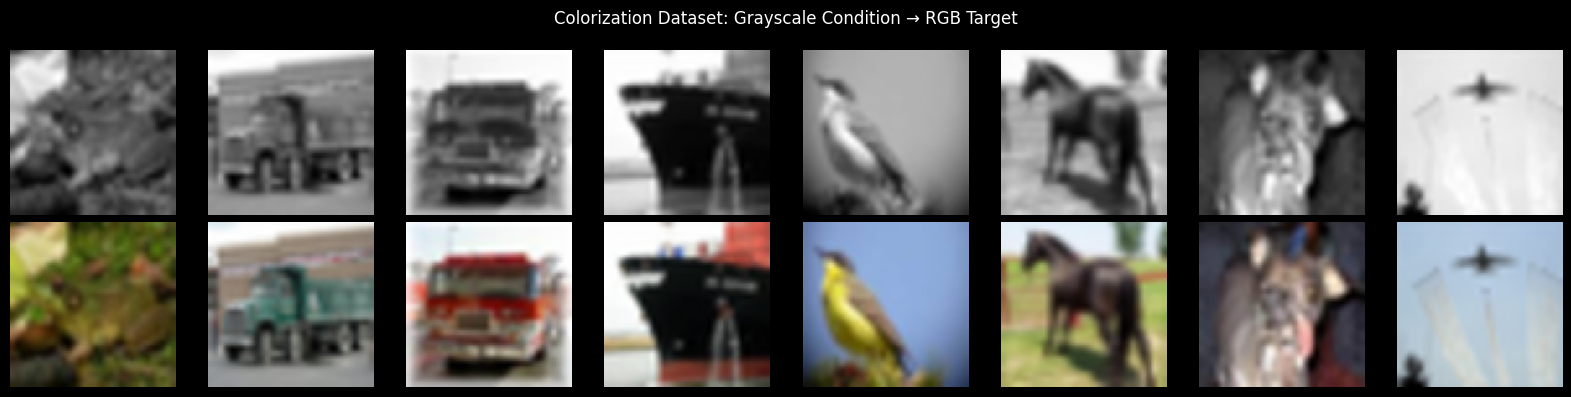

In [39]:
class ColorizationDataset(Dataset):
    def __init__(self, sr_dataset):
        self.sr_dataset = sr_dataset
        self.to_gray = transforms.Grayscale(num_output_channels=1)

    def __len__(self):
        return len(self.sr_dataset)

    def __getitem__(self, idx):
        _, color_image = self.sr_dataset[idx]
        gray_image = self.to_gray(color_image)
        return gray_image, color_image

color_train_dataset = ColorizationDataset(sr_train_dataset)
color_val_dataset = ColorizationDataset(sr_val_dataset)
color_test_dataset = ColorizationDataset(sr_test_dataset)

color_train_loader = DataLoader(color_train_dataset, shuffle=True, **loader_kwargs)
color_val_loader = DataLoader(color_val_dataset, shuffle=False, **loader_kwargs)
color_test_loader = DataLoader(color_test_dataset, shuffle=False, **loader_kwargs)

print(f"Colorization train pairs: {len(color_train_dataset):,}")
print(f"Colorization validation pairs: {len(color_val_dataset):,}")
print(f"Colorization test pairs: {len(color_test_dataset):,}")

gray_batch, color_batch = next(iter(color_train_loader))
num_show = min(8, len(gray_batch))
fig, axes = plt.subplots(2, num_show, figsize=(2 * num_show, 4))
fig.suptitle("Colorization Dataset: Grayscale Condition → RGB Target")
for index in range(num_show):
    gray_vis = ((gray_batch[index].squeeze().cpu() + 1) / 2).clamp(0, 1)
    color_vis = ((color_batch[index].cpu() + 1) / 2).clamp(0, 1)
    axes[0, index].imshow(gray_vis, cmap="gray")
    axes[1, index].imshow(color_vis.permute(1, 2, 0))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Grayscale", rotation=0, ha="right", va="center")
axes[1, 0].set_ylabel("RGB target", rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()

##TODO 2: Create Colorization U-Net



In [40]:
colorization_unet = ConditionalUNet(
    in_channels=3,
    condition_channels=1,
    out_channels=3,
    model_channels=MODEL_CHANNELS,
    channel_mult=CHANNEL_MULT,
    num_res_blocks=2,
    attention_resolutions=ATTENTION_RESOLUTIONS,
    dropout=0.1,
    use_multiscale_features=True,
).to(device)

color_params = sum(parameter.numel() for parameter in colorization_unet.parameters())
print(f"Colorization U-Net created: {color_params / 1e6:.2f}M parameters")

test_gray = torch.randn(2, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)
test_color_noisy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
test_t = torch.randint(0, TIMESTEPS, (2,), device=device)
with torch.no_grad():
    gray_features = feature_extractor(test_gray)
    color_output = colorization_unet(test_color_noisy, test_t, test_gray, gray_features)
print(f"Colorization forward output: {tuple(color_output.shape)}")
assert color_output.shape == test_color_noisy.shape

Colorization U-Net created: 20.07M parameters
Colorization forward output: (2, 3, 64, 64)


##TODO 3: Train Colorization Model


Training: colorization
Epochs: 40 | AMP: True | Checkpoints: checkpoints


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 001/40 | train=0.067535 | val=0.012731 | lr=9.98e-05
  Saved best checkpoint: checkpoints/colorization_best.pt


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

... (111 outputs left out)

Epoch 039/40 | train=0.003710 | val=0.003409 | lr=1.54e-07


  0%|          | 0/704 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 040/40 | train=0.003618 | val=0.003577 | lr=0.00e+00
Best validation loss: 0.003180


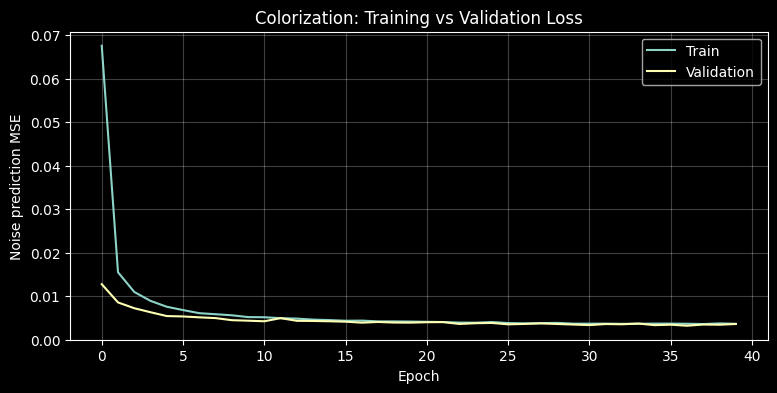

In [41]:
def train_colorization_diffusion(unet, feature_extractor, dataloader, val_dataloader, schedule,
                                 epochs=40, lr=1e-4, use_amp=USE_AMP):
    return train_conditional_diffusion(
        unet, feature_extractor, dataloader, val_dataloader, schedule,
        task_name="colorization", epochs=epochs, lr=lr, use_amp=use_amp,
    )

colorization_history = None
if TRAIN_COLORIZATION:
    colorization_history = train_colorization_diffusion(
        unet=colorization_unet,
        feature_extractor=feature_extractor,
        dataloader=color_train_loader,
        val_dataloader=color_val_loader,
        schedule=schedule,
        epochs=COLORIZATION_EPOCHS,
        lr=1e-4,
    )
    plt.figure(figsize=(9, 4))
    plt.plot(colorization_history["train_loss"], label="Train")
    plt.plot(colorization_history["val_loss"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Noise prediction MSE")
    plt.title("Colorization: Training vs Validation Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("Colorization training skipped. Set TRAIN_COLORIZATION = True to start.")


@torch.no_grad()
def sample_colorization(unet, feature_extractor, schedule, gray_images,
                        num_steps=50, sampler="ddim", eta=0.0):
    return sample_conditional(
        unet, feature_extractor, schedule, gray_images,
        num_steps=num_steps, sampler=sampler, eta=eta,
    )

##Colorization Results



/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:684: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)


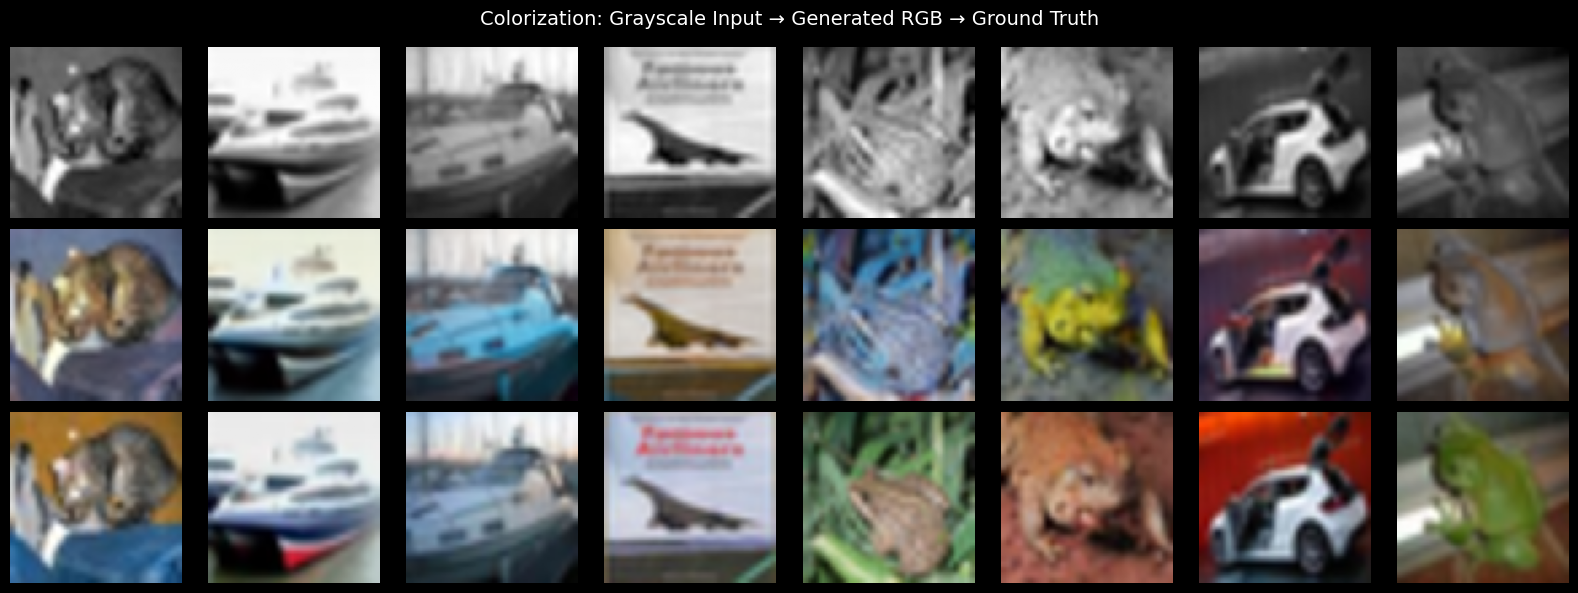

Held-out colorization test metrics (mean over evaluated images):
  model_psnr: 22.3368
  model_ssim: 0.9064
  baseline_psnr: 22.9884
  baseline_ssim: 0.9218


In [43]:
RUN_COLORIZATION_TEST_EVALUATION = True
if RUN_COLORIZATION_TEST_EVALUATION:
    checkpoint_path = CHECKPOINT_DIR / "colorization_best.pt"
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        colorization_unet.load_state_dict(checkpoint["model_state_dict"])

    gray_eval, color_eval = next(iter(color_test_loader))
    gray_eval = gray_eval[:8].to(device)
    color_eval = color_eval[:8].to(device)
    generated_color = sample_colorization(
        colorization_unet, feature_extractor, schedule, gray_eval,
        num_steps=50, sampler="ddim",
    )
    plot_restoration_results(
        gray_eval, generated_color, color_eval,
        "Colorization: Grayscale Input → Generated RGB → Ground Truth",
    )

    color_metrics = evaluate_conditional_model(
        colorization_unet, feature_extractor, schedule, color_test_loader,
        num_steps=50, max_batches=2, samples_per_batch=8,
    )
    print("Held-out colorization test metrics (mean over evaluated images):")
    for name, value in color_metrics.items():
        print(f"  {name}: {value:.4f}")
else:
    print("Colorization test evaluation skipped. Set RUN_COLORIZATION_TEST_EVALUATION = True after training.")